# 02 Machine learning

## Data and split by PSU

In [1]:
import json
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

SEED = 42

df = pd.read_csv("../output/dataset.csv", keep_default_na=False, na_values=[""])
order = json.load(open("../output/cat_order.json"))

PREDICTORS = [c for c in order if c not in ("target", "marital_duration", "contra_behavior_intent")]
for c in PREDICTORS + ["target"]:
    df[c] = pd.Categorical(df[c], categories=order[c], ordered=True)

y = (df["target"] == "Limiting").astype(int).to_numpy()
len(PREDICTORS), df.shape


(24, (17245, 49))

In [2]:
split = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
train_idx, test_idx = next(split.split(df, y, groups=df["psu"]))

pd.DataFrame({
    "women": [len(train_idx), len(test_idx)],
    "PSUs": [df.iloc[train_idx]["psu"].nunique(), df.iloc[test_idx]["psu"].nunique()],
    "limiting": [y[train_idx].mean(), y[test_idx].mean()],
}, index=["train", "test"]).round(3)


,women,PSUs,limiting
train,13802,539,0.613
test,3443,135,0.611


## Encoding

In [3]:
ORDINAL = ["age_cat", "edu_level_name", "husband_edu_cat", "wealth_cat", "living_children_cat",
           "household_size_cat", "marriage_age_cat", "digital_inclusion_cat", "women_autonomy",
           "anxiety_severity", "depression_severity", "ideal_family_size_cat"]
NOMINAL = [c for c in PREDICTORS if c not in ORDINAL]

X = df[PREDICTORS].copy()
for c in ORDINAL:
    X[c] = X[c].cat.codes
X = pd.get_dummies(X, columns=NOMINAL, drop_first=True, dtype=int)

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
X.shape


(17245, 36)

## Baseline model: age group and number of living children

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

B = X[["age_cat", "living_children_cat"]]
baseline = LogisticRegression(max_iter=1000).fit(B.iloc[train_idx], y_train)
roc_auc_score(y_test, baseline.predict_proba(B.iloc[test_idx])[:, 1])


0.8583615192661226

## Boruta within the outer folds

In [5]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import scipy.stats
for name, real in {"float": np.float64, "int": np.int64, "bool": np.bool_,
                   "object": np.object_, "str": np.str_}.items():
    if not hasattr(np, name):
        setattr(np, name, real)
if not hasattr(scipy.stats, "binom_test"):
    scipy.stats.binom_test = lambda x, n=None, p=0.5, alternative="two-sided": \
        scipy.stats.binomtest(int(x), int(n), p, alternative=alternative).pvalue

from boruta import BorutaPy
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold


In [6]:
outer = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
folds = list(outer.split(X_train, y_train, groups=df.iloc[train_idx]["psu"].to_numpy()))

selected = {}
for k, (tr, va) in enumerate(folds):
    rf = RandomForestClassifier(n_jobs=-1, max_depth=5, random_state=SEED)
    boruta = BorutaPy(rf, n_estimators="auto", max_iter=100, random_state=SEED)
    boruta.fit(X_train.iloc[tr].to_numpy(float), y_train[tr])
    selected[k] = X_train.columns[boruta.support_].tolist()


In [7]:
stability = pd.DataFrame({f"fold {k}": X_train.columns.isin(v) for k, v in selected.items()},
                         index=X_train.columns)
stability["times selected"] = stability.sum(axis=1)
stability.sort_values("times selected", ascending=False)


,fold 0,fold 1,fold 2,fold 3,fold 4,fold 5,fold 6,fold 7,fold 8,fold 9,times selected
age_cat,True,True,True,True,True,True,True,True,True,True,10
edu_level_name,True,True,True,True,True,True,True,True,True,True,10
household_size_cat,True,True,True,True,True,True,True,True,True,True,10
wealth_cat,True,True,True,True,True,True,True,True,True,True,10
digital_inclusion_cat,True,True,True,True,True,True,True,True,True,True,10
living_children_cat,True,True,True,True,True,True,True,True,True,True,10
marriage_age_cat,True,True,True,True,True,True,True,True,True,True,10
ideal_family_size_cat,True,True,True,True,True,True,True,True,True,True,10
husband_edu_cat,True,True,True,True,True,True,True,True,True,True,10
women_autonomy,True,True,True,True,True,True,True,True,True,True,10


In [8]:
stability.sort_values("times selected", ascending=False).to_csv("../output/boruta_stability.csv")


## Boruta on the whole training set

In [9]:
rf = RandomForestClassifier(n_jobs=-1, max_depth=5, random_state=SEED)
boruta = BorutaPy(rf, n_estimators="auto", max_iter=100, random_state=SEED)
boruta.fit(X_train.to_numpy(float), y_train)

final_features = X_train.columns[boruta.support_].tolist()
len(final_features), [c for c in final_features if c not in stability.index[stability["times selected"] == 10]]


(25, ['husband_occ_cat_Professional/Technical'])

In [10]:
history = np.asarray(boruta.importance_history_, dtype=float)[1:]
mean_importance = np.nan_to_num(np.nanmean(history, axis=0))

boruta_table = pd.DataFrame({
    "Feature": X_train.columns,
    "Status": np.where(boruta.support_, "Confirmed", np.where(boruta.support_weak_, "Tentative", "Rejected")),
    "Mean importance (%)": mean_importance / mean_importance.sum() * 100,
}).sort_values("Mean importance (%)", ascending=False).reset_index(drop=True)

boruta_table.to_csv("../output/boruta_importance.csv", index=False)
boruta_table.round(1)

,Feature,Status,Mean importance (%)
0,age_cat,Confirmed,31.7
1,residence_duration_15+ years,Confirmed,17.4
2,living_children_cat,Confirmed,16.4
3,residence_duration_0-4 years,Confirmed,12.2
4,edu_level_name,Confirmed,6.1
5,marriage_age_cat,Confirmed,2.6
6,husband_edu_cat,Confirmed,2.6
7,residence_duration_5-14 years,Confirmed,2.2
8,digital_inclusion_cat,Confirmed,1.7
9,household_size_cat,Confirmed,1.7


## Variance inflation factors

In [11]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

Xc = add_constant(X_train[final_features].astype(float))
vif = pd.DataFrame({"Feature": final_features,
                    "VIF": [variance_inflation_factor(Xc.values, i + 1) for i in range(len(final_features))]})
vif = vif.sort_values("VIF", ascending=False).reset_index(drop=True)

vif.to_csv("../output/vif.csv", index=False)
vif.round(2)

,Feature,VIF
0,residence_duration_15+ years,2.32
1,residence_duration_5-14 years,2.08
2,age_cat,2.04
3,residence_duration_0-4 years,2.03
4,edu_level_name,1.97
5,husband_edu_cat,1.86
6,husband_occ_cat_Agriculture,1.75
7,husband_occ_cat_Manual Labor,1.70
8,husband_presence_cat_Living elsewhere,1.67
9,wealth_cat,1.55


## Nested cross-validation

In [12]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

models = {
    "Logistic Regression": (
        Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=5000))]),
        {"clf__C": [0.001, 0.01, 0.1, 1, 10, 100]}, 6),
    "SVM": (
        Pipeline([("scaler", StandardScaler()), ("clf", SVC(probability=True, random_state=SEED, cache_size=1000))]),
        {"clf__C": [0.1, 1, 10], "clf__gamma": ["scale", "auto"]}, 2),
    "Random Forest": (
        RandomForestClassifier(random_state=SEED, n_jobs=1),
        {"n_estimators": [100, 200, 300], "max_depth": [4, 6, 8, None],
         "min_samples_split": [2, 5, 10], "max_features": ["sqrt", "log2"]}, 10),
    "CatBoost": (
        CatBoostClassifier(verbose=0, random_state=SEED, thread_count=1, allow_writing_files=False),
        {"iterations": [100, 200, 300], "depth": [4, 6, 8], "learning_rate": [0.01, 0.05, 0.1],
         "l2_leaf_reg": [1, 3, 5]}, 10),
    "XGBoost": (
        XGBClassifier(eval_metric="logloss", random_state=SEED, n_jobs=1, tree_method="hist"),
        {"n_estimators": [100, 200, 300], "learning_rate": [0.01, 0.05, 0.1], "max_depth": [3, 5, 7],
         "subsample": [0.8, 1.0], "colsample_bytree": [0.8, 1.0]}, 10),
}

groups = df.iloc[train_idx]["psu"].to_numpy()
inner_cv = StratifiedGroupKFold(n_splits=5)
oof = {name: np.zeros(len(y_train)) for name in models}

for k, (tr, va) in enumerate(folds):
    cols = selected[k]
    for name, (model, grid, n_iter) in models.items():
        search = RandomizedSearchCV(model, grid, n_iter=n_iter, cv=inner_cv,
                                    scoring="roc_auc", random_state=SEED, n_jobs=-1)
        search.fit(X_train.iloc[tr][cols], y_train[tr], groups=groups[tr])
        oof[name][va] = search.predict_proba(X_train.iloc[va][cols])[:, 1]


In [13]:
fold_auc = pd.DataFrame({name: [roc_auc_score(y_train[va], oof[name][va]) for _, va in folds]
                         for name in models})
fold_auc.agg(["mean", "std"]).T.round(3)


,mean,std
Logistic Regression,0.898,0.008
SVM,0.896,0.008
Random Forest,0.899,0.008
CatBoost,0.905,0.008
XGBoost,0.905,0.008


In [14]:
rng = np.random.default_rng(SEED)
cluster_ids = np.unique(groups)
rows_by_cluster = {g: np.where(groups == g)[0] for g in cluster_ids}

boot = []
for _ in range(1000):
    drawn = rng.choice(cluster_ids, size=len(cluster_ids), replace=True)
    idx = np.concatenate([rows_by_cluster[g] for g in drawn])
    boot.append({name: roc_auc_score(y_train[idx], oof[name][idx]) for name in oof})
boot = pd.DataFrame(boot)

summary = pd.DataFrame({"AUC": {n: roc_auc_score(y_train, oof[n]) for n in oof},
                        "2.5%": boot.quantile(0.025), "97.5%": boot.quantile(0.975)})
summary.round(3)


,AUC,2.5%,97.5%
Logistic Regression,0.898,0.892,0.903
SVM,0.896,0.891,0.901
Random Forest,0.899,0.894,0.904
CatBoost,0.904,0.899,0.909
XGBoost,0.905,0.900,0.910


In [15]:
d = boot.sub(boot["Logistic Regression"], axis=0)
vs_lr = pd.DataFrame({"difference": summary["AUC"] - summary.loc["Logistic Regression", "AUC"],
                      "2.5%": d.quantile(0.025), "97.5%": d.quantile(0.975)})
vs_lr.round(3)


,difference,2.5%,97.5%
Logistic Regression,0.000,0.000,0.000
SVM,-0.002,-0.004,0.000
Random Forest,0.002,-0.001,0.004
CatBoost,0.007,0.005,0.008
XGBoost,0.007,0.006,0.009


In [16]:
d2 = boot["XGBoost"] - boot["CatBoost"]
pd.Series({"difference": summary.loc["XGBoost", "AUC"] - summary.loc["CatBoost", "AUC"],
           "2.5%": d2.quantile(0.025), "97.5%": d2.quantile(0.975)}).round(3)


difference    0.001
2.5%         -0.000
97.5%         0.001
dtype: float64

## Final models and test AUC

In [17]:
best, test_prob = {}, {}

for name, (model, grid, n_iter) in models.items():
    search = RandomizedSearchCV(model, grid, n_iter=n_iter, cv=inner_cv, scoring="roc_auc",
                                random_state=SEED, n_jobs=-1)
    search.fit(X_train[final_features], y_train, groups=groups)
    best[name] = search.best_estimator_
    test_prob[name] = search.predict_proba(X_test[final_features])[:, 1]


In [18]:
test_groups = df.iloc[test_idx]["psu"].to_numpy()
test_clusters = np.unique(test_groups)
test_rows = {g: np.where(test_groups == g)[0] for g in test_clusters}

boot_test = []
for _ in range(1000):
    drawn = rng.choice(test_clusters, size=len(test_clusters), replace=True)
    idx = np.concatenate([test_rows[g] for g in drawn])
    boot_test.append({name: roc_auc_score(y_test[idx], test_prob[name][idx]) for name in test_prob})
boot_test = pd.DataFrame(boot_test)

auc = {n: roc_auc_score(y_test, test_prob[n]) for n in test_prob}
d = boot_test.sub(boot_test["Logistic Regression"], axis=0)

pd.DataFrame({
    "test AUC": auc,
    "2.5%": boot_test.quantile(0.025), "97.5%": boot_test.quantile(0.975),
    "diff vs LR": {n: auc[n] - auc["Logistic Regression"] for n in auc},
    "diff 2.5%": d.quantile(0.025), "diff 97.5%": d.quantile(0.975),
}).round(3)


,test AUC,2.5%,97.5%,diff vs LR,diff 2.5%,diff 97.5%
Logistic Regression,0.903,0.891,0.914,0.000,0.000,0.000
SVM,0.900,0.888,0.912,-0.003,-0.005,0.001
Random Forest,0.897,0.885,0.909,-0.006,-0.011,-0.001
CatBoost,0.907,0.895,0.918,0.004,0.001,0.007
XGBoost,0.907,0.895,0.918,0.004,0.001,0.007


## ROC curves (Fig. 1)

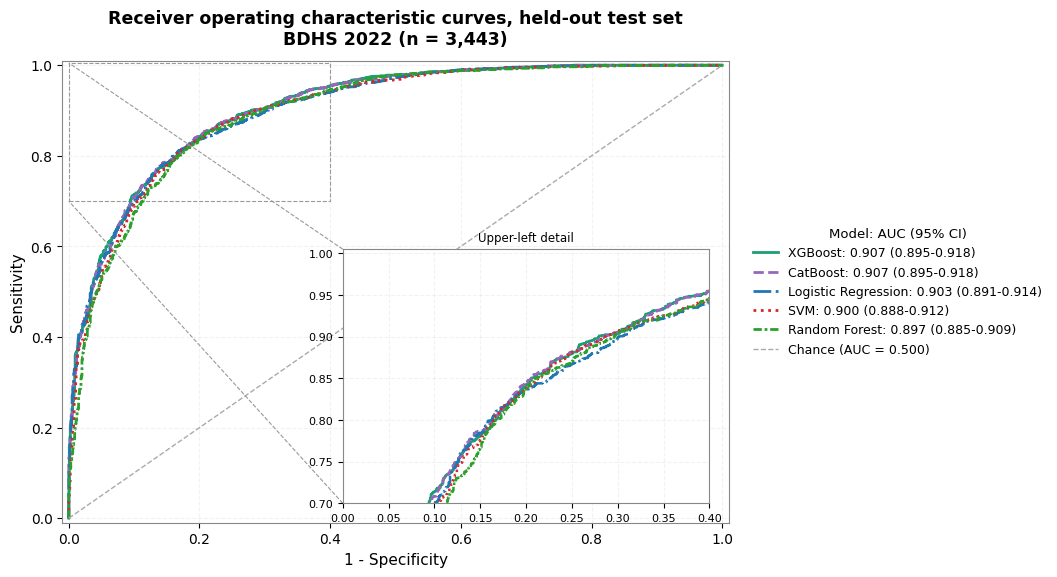

In [19]:
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
from sklearn.metrics import roc_curve

colors = {"Logistic Regression": "#1f77b4", "Random Forest": "#2ca02c", "XGBoost": "#1D9E75",
          "CatBoost": "#9467bd", "SVM": "#d62728"}
styles = ["-", "--", "-.", ":", (0, (3, 1, 1, 1))]

with plt.rc_context({"axes.edgecolor": "#888888"}):
    fig, ax = plt.subplots(figsize=(8.6, 6.0))
    axins = inset_axes(ax, width="55%", height="55%", loc="lower right", borderpad=1.4)

    for i, name in enumerate(sorted(auc, key=auc.get, reverse=True)):
        fpr, tpr, _ = roc_curve(y_test, test_prob[name])
        lo, hi = boot_test[name].quantile(0.025), boot_test[name].quantile(0.975)
        ax.plot(fpr, tpr, color=colors[name], lw=2.0, ls=styles[i],
                label=f"{name}: {auc[name]:.3f} ({lo:.3f}-{hi:.3f})")
        axins.plot(fpr, tpr, color=colors[name], lw=1.8, ls=styles[i])

    ax.plot([0, 1], [0, 1], color="#AAAAAA", lw=1.0, ls="--", label="Chance (AUC = 0.500)")
    ax.set_xlim(-0.01, 1.01)
    ax.set_ylim(-0.01, 1.01)
    ax.set_xlabel("1 - Specificity", fontsize=11)
    ax.set_ylabel("Sensitivity", fontsize=11)
    ax.set_title("Receiver operating characteristic curves, held-out test set\n"
                 f"BDHS 2022 (n = {len(y_test):,})", fontsize=12.5, fontweight="bold", pad=12)
    ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False,
              fontsize=9, title="Model: AUC (95% CI)", title_fontsize=9.5)
    ax.grid(ls="--", alpha=0.25, color="#CCCCCC")
    ax.set_axisbelow(True)

    axins.set_xlim(0.0, 0.40)
    axins.set_ylim(0.70, 1.005)
    axins.grid(ls="--", alpha=0.25, color="#CCCCCC")
    axins.tick_params(labelsize=8)
    axins.set_title("Upper-left detail", fontsize=8.5)
    mark_inset(ax, axins, loc1=2, loc2=3, ec="#999999", lw=0.8, ls="--")

    fig.savefig("../output/fig1_roc.png", dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()


## Calibration

In [20]:
import statsmodels.api as sm
from sklearn.metrics import brier_score_loss

def calibration(y, p):
    lp = np.log(p / (1 - p))
    slope = sm.Logit(y, sm.add_constant(lp)).fit(disp=0).params[1]
    intercept = sm.GLM(y, np.ones(len(y)), family=sm.families.Binomial(), offset=lp).fit().params[0]
    return {"Brier": brier_score_loss(y, p), "intercept": intercept, "slope": slope}

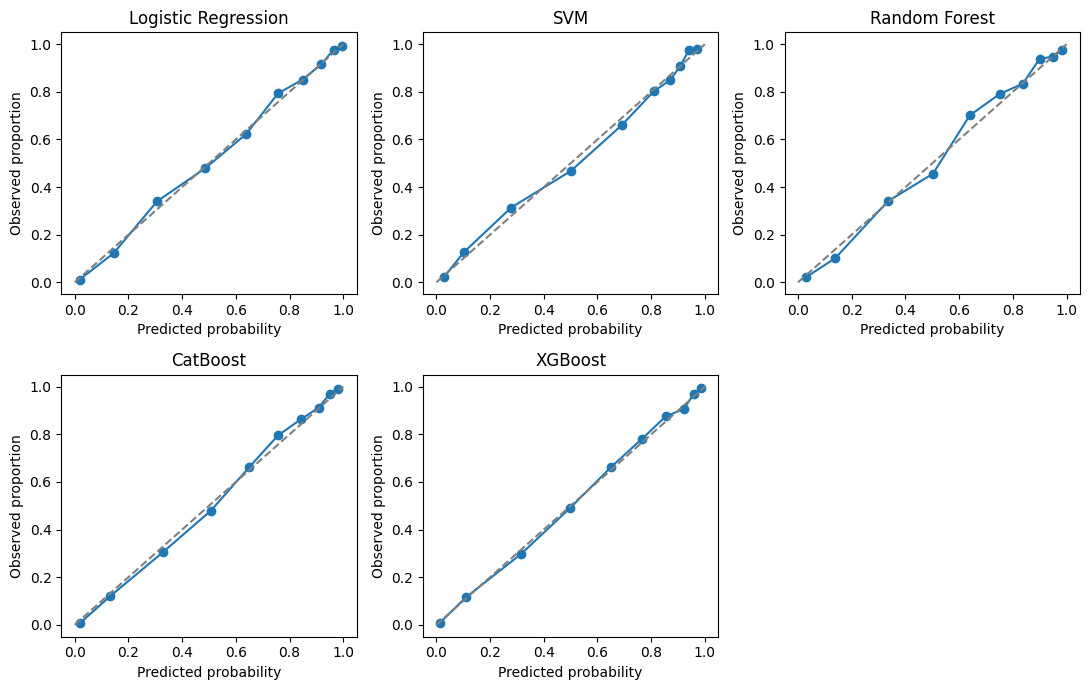

In [21]:
from sklearn.calibration import calibration_curve

fig, axes = plt.subplots(2, 3, figsize=(11, 7), sharex=True, sharey=True)
for ax, name in zip(axes.flat, test_prob):
    observed, predicted = calibration_curve(y_test, test_prob[name], n_bins=10, strategy="quantile")
    ax.plot(predicted, observed, marker="o")
    ax.plot([0, 1], [0, 1], ls="--", color="grey")
    ax.set_title(name)
    ax.set_xlabel("Predicted probability")
    ax.set_ylabel("Observed proportion")
    ax.tick_params(labelbottom=True, labelleft=True)
axes.flat[5].set_visible(False)
fig.tight_layout()
fig.savefig("../output/fig_calibration.png", dpi=300, bbox_inches="tight")
plt.show()


## Thresholds

In [22]:
from sklearn.metrics import confusion_matrix

rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    tn, fp, fn, tp = confusion_matrix(y_test, test_prob["XGBoost"] >= t).ravel()
    rows.append({"threshold": t, "sensitivity": tp / (tp + fn), "specificity": tn / (tn + fp),
                 "PPV": tp / (tp + fp), "NPV": tn / (tn + fn), "accuracy": (tp + tn) / len(y_test)})

pd.DataFrame(rows).round(3)

,threshold,sensitivity,specificity,PPV,NPV,accuracy
0,0.3,0.967,0.566,0.777,0.917,0.811
1,0.4,0.934,0.649,0.806,0.862,0.823
2,0.5,0.895,0.729,0.838,0.816,0.830
3,0.6,0.836,0.805,0.870,0.758,0.824
4,0.7,0.763,0.868,0.901,0.700,0.804


## Confusion matrix

In [23]:
tn, fp, fn, tp = confusion_matrix(y_test, test_prob["XGBoost"] >= 0.5).ravel()
pd.DataFrame([[tp, fn], [fp, tn]],
             index=["Observed: limiting", "Observed: non-limiting"],
             columns=["Predicted: limiting", "Predicted: non-limiting"])

,Predicted: limiting,Predicted: non-limiting
Observed: limiting,1881,221
Observed: non-limiting,364,977


## Incremental predictive value

In [24]:
from sklearn.base import clone

core = [v for v in PREDICTORS if v not in ("residence_duration", "digital_inclusion_cat",
                                           "anxiety_severity", "depression_severity")]
steps = {
    "Core": core,
    "+ residence duration": core + ["residence_duration"],
    "+ digital inclusion": core + ["residence_duration", "digital_inclusion_cat"],
    "+ anxiety and depression": PREDICTORS,
}

step_prob = {}
for name, variables in steps.items():
    cols = [c for c in X.columns if c in variables or any(c.startswith(v + "_") for v in variables)]
    model = clone(best["XGBoost"]).fit(X_train[cols], y_train)
    step_prob[name] = model.predict_proba(X_test[cols])[:, 1]


In [25]:
boot_steps = []
for _ in range(1000):
    drawn = rng.choice(test_clusters, size=len(test_clusters), replace=True)
    idx = np.concatenate([test_rows[g] for g in drawn])
    boot_steps.append({n: roc_auc_score(y_test[idx], p[idx]) for n, p in step_prob.items()})
boot_steps = pd.DataFrame(boot_steps)

auc_steps = pd.Series({n: roc_auc_score(y_test, p) for n, p in step_prob.items()})
change = boot_steps.diff(axis=1)
step_cal = pd.DataFrame({n: calibration(y_test, np.clip(p, 1e-6, 1 - 1e-6)) for n, p in step_prob.items()}).T

pd.DataFrame({
    "test AUC": auc_steps,
    "change": auc_steps.diff(),
    "change 2.5%": change.quantile(0.025),
    "change 97.5%": change.quantile(0.975),
    "Brier": step_cal["Brier"],
    "calibration intercept": step_cal["intercept"],
    "calibration slope": step_cal["slope"],
}).round(4)


,test AUC,change,change 2.5%,change 97.5%,Brier,calibration intercept,calibration slope
Core,0.9043,NaN,NaN,NaN,0.1198,-0.0052,1.0604
+ residence duration,0.9065,0.0022,-0.0003,0.0048,0.1182,0.0143,1.0346
+ digital inclusion,0.9068,0.0002,-0.0010,0.0014,0.1182,0.0211,1.0433
+ anxiety and depression,0.9068,0.0000,-0.0007,0.0008,0.1181,0.0203,1.0452


## Subgroups

In [26]:
test_df = df.iloc[test_idx]
p = test_prob["XGBoost"]
boot_idx = [np.concatenate([test_rows[g] for g in rng.choice(test_clusters, size=len(test_clusters), replace=True)])
            for _ in range(1000)]

rows = []
for var in ["age_cat", "living_children_cat", "residence_name", "wealth_cat", "residence_duration"]:
    for level in test_df[var].cat.categories:
        mask = (test_df[var] == level).to_numpy()
        aucs = []
        for idx in boot_idx:
            m = mask[idx]
            if len(np.unique(y_test[idx][m])) == 2:
                aucs.append(roc_auc_score(y_test[idx][m], p[idx][m]))
        rows.append({"variable": var, "group": level, "n": mask.sum(),
                     "observed %": y_test[mask].mean() * 100, "predicted %": p[mask].mean() * 100,
                     "AUC": roc_auc_score(y_test[mask], p[mask]),
                     "2.5%": np.quantile(aucs, 0.025), "97.5%": np.quantile(aucs, 0.975)})

pd.DataFrame(rows).round(3)


,variable,group,n,observed %,predicted %,AUC,2.5%,97.5%
0,age_cat,15-24 (Younger),854,16.862,16.691999,0.837,0.805,0.867
1,age_cat,25-34 (Middle-aged),1274,59.733,59.694000,0.793,0.766,0.820
2,age_cat,35-49 (Older),1315,91.027,90.416000,0.824,0.783,0.865
3,living_children_cat,0 children,357,1.681,2.239000,0.912,0.849,0.967
4,living_children_cat,1-3 children,2722,63.813,63.605999,0.855,0.839,0.871
5,living_children_cat,4+ children,364,98.626,96.886002,0.801,0.331,0.946
6,residence_name,Urban,1162,58.778,58.483002,0.893,0.870,0.914
7,residence_name,Rural,2281,62.210,61.923000,0.913,0.901,0.926
8,wealth_cat,Poor,1217,61.791,62.812000,0.911,0.889,0.930
9,wealth_cat,Middle,679,64.212,61.383999,0.915,0.891,0.936


In [27]:
p = test_prob["XGBoost"]

rows = []
for var in ["age_cat", "living_children_cat", "residence_name", "wealth_cat", "residence_duration"]:
    for level in test_df[var].cat.categories:
        mask = (test_df[var] == level).to_numpy()
        gaps = [(y_test[idx][mask[idx]].mean() - p[idx][mask[idx]].mean()) * 100 for idx in boot_idx]
        rows.append({"variable": var, "group": level,
                     "observed − predicted (points)": (y_test[mask].mean() - p[mask].mean()) * 100,
                     "2.5%": np.quantile(gaps, 0.025), "97.5%": np.quantile(gaps, 0.975)})

subgroup_calibration = pd.DataFrame(rows).round(2)
subgroup_calibration.to_csv("../output/subgroup_calibration.csv", index=False)
subgroup_calibration

,variable,group,observed − predicted (points),2.5%,97.5%
0,age_cat,15-24 (Younger),0.17,-1.95,2.17
1,age_cat,25-34 (Middle-aged),0.04,-2.44,2.33
2,age_cat,35-49 (Older),0.61,-0.85,2.00
3,living_children_cat,0 children,-0.56,-1.70,0.76
4,living_children_cat,1-3 children,0.21,-1.25,1.71
5,living_children_cat,4+ children,1.74,0.22,2.99
6,residence_name,Urban,0.30,-1.75,2.21
7,residence_name,Rural,0.29,-1.41,1.83
8,wealth_cat,Poor,-1.02,-3.43,1.63
9,wealth_cat,Middle,2.83,0.19,5.33


## Sampling weights

In [28]:
w_train = df.iloc[train_idx]["weight"].to_numpy()
w_test = df.iloc[test_idx]["weight"].to_numpy()

weight_argument = {"XGBoost": "sample_weight", "CatBoost": "sample_weight", "Random Forest": "sample_weight",
                   "Logistic Regression": "clf__sample_weight", "SVM": "clf__sample_weight"}

rows = []
for name, argument in weight_argument.items():
    model = clone(best[name]).fit(X_train[final_features], y_train, **{argument: w_train})
    p_w = model.predict_proba(X_test[final_features])[:, 1]
    aucs = [roc_auc_score(y_test[idx], p_w[idx], sample_weight=w_test[idx]) for idx in boot_idx]
    rows.append({"model": name,
                 "unweighted fit, unweighted AUC": roc_auc_score(y_test, test_prob[name]),
                 "unweighted fit, weighted AUC": roc_auc_score(y_test, test_prob[name], sample_weight=w_test),
                 "weighted fit, weighted AUC": roc_auc_score(y_test, p_w, sample_weight=w_test),
                 "2.5%": np.quantile(aucs, 0.025), "97.5%": np.quantile(aucs, 0.975)})

survey_weight = pd.DataFrame(rows).round(3)
survey_weight.to_csv("../output/survey_weight_sensitivity.csv", index=False)
survey_weight


,model,"unweighted fit, unweighted AUC","unweighted fit, weighted AUC","weighted fit, weighted AUC",2.5%,97.5%
0,XGBoost,0.907,0.909,0.908,0.897,0.920
1,CatBoost,0.907,0.908,0.908,0.897,0.920
2,Random Forest,0.897,0.898,0.898,0.886,0.912
3,Logistic Regression,0.903,0.905,0.905,0.893,0.917
4,SVM,0.900,0.903,0.903,0.891,0.915


## Class weighting

In [29]:
spw = (y_train == 0).sum() / (y_train == 1).sum()
xgb_class_weighted = clone(best["XGBoost"]).set_params(scale_pos_weight=spw).fit(X_train[final_features], y_train)

versions = {
    "without class weighting": np.clip(test_prob["XGBoost"], 1e-6, 1 - 1e-6),
    "with class weighting": np.clip(xgb_class_weighted.predict_proba(X_test[final_features])[:, 1], 1e-6, 1 - 1e-6),
}

rows = {}
for label, prob in versions.items():
    estimate = calibration(y_test, prob)
    boots = pd.DataFrame([calibration(y_test[idx], prob[idx]) for idx in boot_idx])
    rows[label] = {"AUC": f"{roc_auc_score(y_test, prob):.3f}",
                   "observed %": f"{y_test.mean() * 100:.1f}",
                   "mean predicted %": f"{prob.mean() * 100:.1f}"}
    rows[label] |= {k: f"{estimate[k]:.3f} ({boots[k].quantile(0.025):.3f}–{boots[k].quantile(0.975):.3f})"
                    for k in estimate}

pd.DataFrame(rows).T

,AUC,observed %,mean predicted %,Brier,intercept,slope
without class weighting,0.907,61.1,60.8,0.118 (0.111–0.125),0.024 (-0.080–0.126),1.049 (0.978–1.134)
with class weighting,0.907,61.1,55.1,0.123 (0.116–0.130),0.473 (0.368–0.575),1.057 (0.984–1.140)


## Table 2 and calibration table

In [30]:
from sklearn.metrics import average_precision_score

cv = fold_auc.agg(["mean", "std"]).T

perf_rows, cal_rows = [], []
for name in cv["mean"].sort_values(ascending=False).index:
    p = np.clip(test_prob[name], 1e-6, 1 - 1e-6)
    tn, fp, fn, tp = confusion_matrix(y_test, p >= 0.5).ravel()
    cal = calibration(y_test, p)
    cal_boot = pd.DataFrame([calibration(y_test[idx], p[idx]) for idx in boot_idx])
    lo, hi = boot_test[name].quantile(0.025), boot_test[name].quantile(0.975)
    perf_rows.append({
        "Model": name,
        "CV AUC (mean ± SD)": f"{cv.loc[name, 'mean']:.3f} ± {cv.loc[name, 'std']:.3f}",
        "Test AUC (95% CI)": f"{roc_auc_score(y_test, p):.3f} ({lo:.3f}–{hi:.3f})",
        "PR-AUC": f"{average_precision_score(y_test, p):.3f}",
        "Accuracy": f"{(tp + tn) / len(y_test) * 100:.1f}",
        "Precision": f"{tp / (tp + fp) * 100:.1f}",
        "Sensitivity": f"{tp / (tp + fn) * 100:.1f}",
        "Specificity": f"{tn / (tn + fp) * 100:.1f}",
        "F1-score": f"{2 * tp / (2 * tp + fp + fn):.3f}"})
    cal_rows.append({"Model": name} | {
        label: f"{cal[k]:.3f} ({cal_boot[k].quantile(0.025):.3f}–{cal_boot[k].quantile(0.975):.3f})"
        for label, k in [("Brier score (95% CI)", "Brier"), ("Calibration intercept (95% CI)", "intercept"),
                         ("Calibration slope (95% CI)", "slope")]})

table2 = pd.DataFrame(perf_rows)
table3 = pd.DataFrame(cal_rows)
table2.to_csv("../output/table2_performance.csv", index=False)
table3.to_csv("../output/table3_calibration.csv", index=False)
table2


,Model,CV AUC (mean ± SD),Test AUC (95% CI),PR-AUC,Accuracy,Precision,Sensitivity,Specificity,F1-score
0,XGBoost,0.905 ± 0.008,0.907 (0.895–0.918),0.935,83.0,83.8,89.5,72.9,0.865
1,CatBoost,0.905 ± 0.008,0.907 (0.895–0.918),0.935,82.7,83.5,89.4,72.3,0.863
2,Random Forest,0.899 ± 0.008,0.897 (0.885–0.909),0.924,82.5,83.3,89.1,72.0,0.861
3,Logistic Regression,0.898 ± 0.008,0.903 (0.891–0.914),0.933,82.1,83.6,88.0,72.9,0.857
4,SVM,0.896 ± 0.008,0.900 (0.888–0.912),0.928,82.7,83.5,89.4,72.3,0.864


In [31]:
table3

,Model,Brier score (95% CI),Calibration intercept (95% CI),Calibration slope (95% CI)
0,XGBoost,0.118 (0.111–0.125),0.024 (-0.080–0.126),1.049 (0.978–1.134)
1,CatBoost,0.119 (0.112–0.126),0.025 (-0.073–0.122),1.135 (1.059–1.224)
2,Random Forest,0.123 (0.116–0.130),0.033 (-0.071–0.135),1.089 (1.016–1.175)
3,Logistic Regression,0.122 (0.115–0.130),0.022 (-0.083–0.125),1.044 (0.973–1.128)
4,SVM,0.122 (0.115–0.130),0.005 (-0.101–0.114),1.003 (0.944–1.072)


## XGBoost and the baseline model

In [32]:
p_base = baseline.predict_proba(B.iloc[test_idx])[:, 1]
p_xgb = test_prob["XGBoost"]

diff = [roc_auc_score(y_test[idx], p_xgb[idx]) - roc_auc_score(y_test[idx], p_base[idx]) for idx in boot_idx]

pd.Series({"baseline AUC": roc_auc_score(y_test, p_base),
           "XGBoost AUC": roc_auc_score(y_test, p_xgb),
           "difference": roc_auc_score(y_test, p_xgb) - roc_auc_score(y_test, p_base),
           "2.5%": np.quantile(diff, 0.025), "97.5%": np.quantile(diff, 0.975)}).round(3)

baseline AUC    0.858
XGBoost AUC     0.907
difference      0.048
2.5%            0.042
97.5%           0.055
dtype: float64

## Hyperparameters

In [33]:
tuned = {name: {k: best[name].get_params()[k] for k in grid} for name, (model, grid, n_iter) in models.items()}
hyperparameters = pd.DataFrame({name: pd.Series(v) for name, v in tuned.items()}).T
hyperparameters.to_csv("../output/hyperparameters.csv")
hyperparameters

,clf__C,clf__gamma,colsample_bytree,depth,iterations,l2_leaf_reg,learning_rate,max_depth,max_features,min_samples_split,n_estimators,subsample
Logistic Regression,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SVM,0.1,scale,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Random Forest,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,sqrt,10,300,NaN
CatBoost,NaN,NaN,NaN,6.0,100.0,3.0,0.05,NaN,NaN,NaN,NaN,NaN
XGBoost,NaN,NaN,1.0,NaN,NaN,NaN,0.05,3.0,NaN,NaN,300.0,1.0


In [34]:
search_space = pd.DataFrame({"search space": {n: str(g) for n, (m, g, k) in models.items()},
                             "candidates sampled": {n: k for n, (m, g, k) in models.items()}})
search_space.to_csv("../output/search_space.csv")
search_space

,search space,candidates sampled
Logistic Regression,"{'clf__C': [0.001, 0.01, 0.1, 1, 10, 100]}",6
SVM,"{'clf__C': [0.1, 1, 10], 'clf__gamma': ['scale...",2
Random Forest,"{'n_estimators': [100, 200, 300], 'max_depth':...",10
CatBoost,"{'iterations': [100, 200, 300], 'depth': [4, 6...",10
XGBoost,"{'n_estimators': [100, 200, 300], 'learning_ra...",10


## SHAP values

In [55]:
import shap

xgb = best["XGBoost"]
X_shap = X_test[final_features].astype(float)
background = X_train[final_features].astype(float).sample(100, random_state=SEED)

sv = shap.TreeExplainer(xgb, data=background, feature_perturbation="interventional")(X_shap)
sv.shape


 96%|=================== | 3302/3443 [00:24<00:01]       

(3443, 25)

## Predictor-level SHAP importance

In [36]:
NAMES = {
    "age_cat": "Age group", "division_name": "Division", "residence_name": "Place of residence",
    "residence_duration": "Residence duration", "edu_level_name": "Education", "religion_cat": "Religion",
    "household_size_cat": "Household size", "hh_head_sex_cat": "Sex of household head",
    "media_exposure": "Media exposure", "wealth_cat": "Wealth", "digital_inclusion_cat": "Digital inclusion",
    "child_death_experience": "Child death experience", "is_pregnant": "Currently pregnant",
    "living_children_cat": "Living children", "husband_presence_cat": "Husband's residence",
    "marriage_age_cat": "Age at marriage", "ideal_family_size_cat": "Ideal family size",
    "husband_edu_cat": "Husband's education", "husband_occ_cat": "Husband's occupation",
    "working_status": "Working status", "women_autonomy": "Women's autonomy",
    "justifies_violence": "Justifies wife-beating", "anxiety_severity": "Anxiety (GAD-7)",
    "depression_severity": "Depression (PHQ-9)",
}

owner = {f: max((p for p in PREDICTORS if f == p or f.startswith(p + "_")), key=len) for f in final_features}
labels = [NAMES[owner[f]] if f == owner[f] else f"{NAMES[owner[f]]}: {f[len(owner[f]) + 1:]}"
          for f in final_features]

def predictor_importance(values):
    return pd.DataFrame(values, columns=final_features).T.groupby(owner).sum().T.abs().mean()

grouped = predictor_importance(sv.values).reindex(PREDICTORS).fillna(0)
predictor_table = pd.DataFrame({
    "Predictor": [NAMES[p] for p in PREDICTORS],
    "Type": ["ordinal" if p in ORDINAL else "nominal" for p in PREDICTORS],
    "Reference category": [order[p][0] if p in NOMINAL else "" for p in PREDICTORS],
    "Selected by Boruta": ["yes" if p in owner.values() else "no" for p in PREDICTORS],
    "Mean |SHAP|": grouped.to_numpy()})
predictor_table["% of total"] = predictor_table["Mean |SHAP|"] / predictor_table["Mean |SHAP|"].sum() * 100
predictor_table = predictor_table.sort_values("Mean |SHAP|", ascending=False).reset_index(drop=True)

predictor_table.round(3).to_csv("../output/table_s4_predictor_shap.csv", index=False)
predictor_table.round(3)


,Predictor,Type,Reference category,Selected by Boruta,Mean |SHAP|,% of total
0,Age group,ordinal,,yes,1.067,28.494
1,Living children,ordinal,,yes,0.604,16.134
2,Ideal family size,ordinal,,yes,0.335,8.944
3,Residence duration,nominal,Always resident,yes,0.311,8.310
4,Age at marriage,ordinal,,yes,0.295,7.884
5,Household size,ordinal,,yes,0.288,7.698
6,Education,ordinal,,yes,0.200,5.343
7,Currently pregnant,nominal,No,yes,0.119,3.165
8,Digital inclusion,ordinal,,yes,0.118,3.150
9,Husband's education,ordinal,,yes,0.080,2.148


## Feature-level SHAP importance

In [37]:
feature_table = pd.DataFrame({"Feature": labels, "Mean |SHAP|": np.abs(sv.values).mean(axis=0)})
feature_table["% of total"] = feature_table["Mean |SHAP|"] / feature_table["Mean |SHAP|"].sum() * 100
feature_table = feature_table.sort_values("Mean |SHAP|", ascending=False).reset_index(drop=True)

feature_table.round(3).to_csv("../output/table_s4_feature_shap.csv", index=False)
feature_table.round(3)


,Feature,Mean |SHAP|,% of total
0,Age group,1.067,27.562
1,Living children,0.604,15.607
2,Ideal family size,0.335,8.652
3,Age at marriage,0.295,7.626
4,Household size,0.288,7.446
5,Residence duration: 15+ years,0.208,5.381
6,Education,0.200,5.168
7,Residence duration: 0-4 years,0.173,4.481
8,Currently pregnant: Yes,0.119,3.061
9,Digital inclusion,0.118,3.047


## SHAP summary plot (Fig. 2)

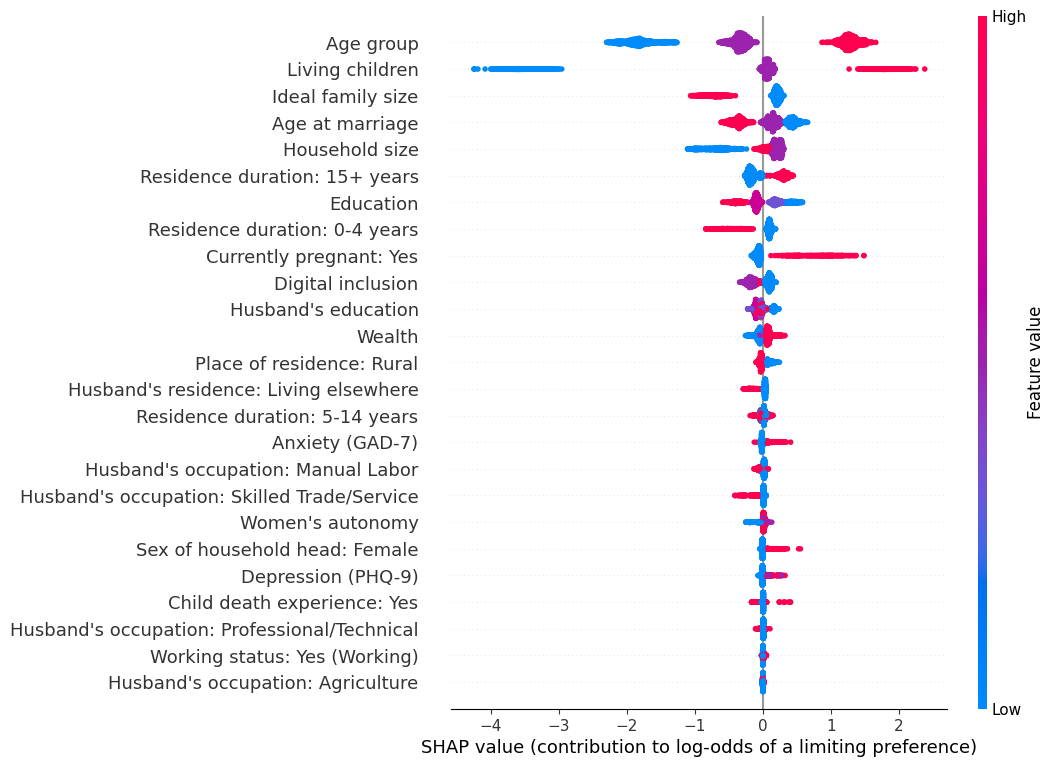

In [38]:
sv_labelled = shap.Explanation(sv.values, base_values=sv.base_values, data=sv.data, feature_names=labels)

shap.plots.beeswarm(sv_labelled, max_display=len(final_features), plot_size=(8, 9), show=False)
plt.xlabel("SHAP value (contribution to log-odds of a limiting preference)")
plt.savefig("../output/fig2_shap_beeswarm.png", dpi=300, bbox_inches="tight")
plt.show()


## Predictor-level SHAP plot

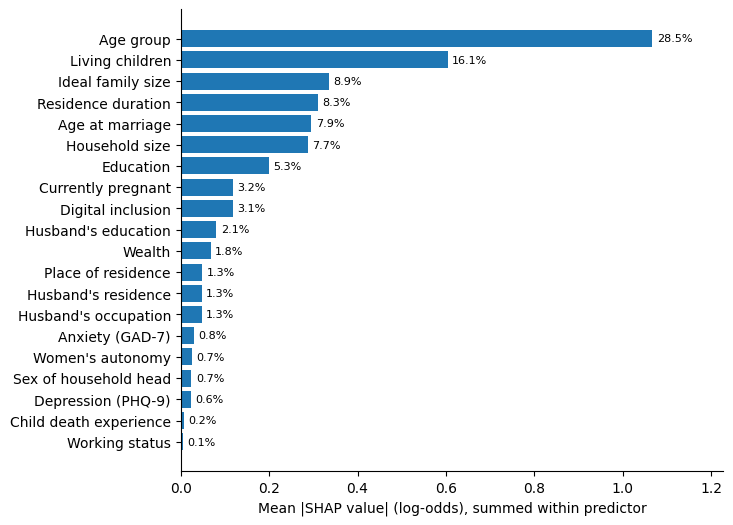

In [39]:
shown = predictor_table[predictor_table["Mean |SHAP|"] > 0].iloc[::-1]

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(shown["Predictor"], shown["Mean |SHAP|"], color="#1f77b4")
for i, (value, pct) in enumerate(zip(shown["Mean |SHAP|"], shown["% of total"])):
    ax.text(value + 0.01, i, f"{pct:.1f}%", va="center", fontsize=8)
ax.set_xlim(0, shown["Mean |SHAP|"].max() * 1.15)
ax.set_xlabel("Mean |SHAP value| (log-odds), summed within predictor")
ax.spines[["top", "right"]].set_visible(False)
fig.savefig("../output/fig_s4_predictor_shap.png", dpi=300, bbox_inches="tight")
plt.show()


## Robustness of SHAP importance

In [40]:
from scipy.stats import spearmanr

background_1000 = X_train[final_features].astype(float).sample(1000, random_state=SEED + 1)
alternatives = {
    "Interventional, 100 background (main)": sv.values,
    "Interventional, 1000 background": shap.TreeExplainer(
        xgb, data=shap.maskers.Independent(background_1000, max_samples=1000))(X_shap).values,
    "Tree-path-dependent": shap.TreeExplainer(xgb, feature_perturbation="tree_path_dependent")(X_shap).values,
}

robustness = pd.DataFrame({k: predictor_importance(v) / predictor_importance(v).sum() * 100
                           for k, v in alternatives.items()})
robustness = robustness.sort_values(robustness.columns[0], ascending=False).rename(index=NAMES)
robustness.round(1).to_csv("../output/shap_robustness.csv")
robustness.round(1)


100%|===================| 3434/3443 [03:09<00:00]        

,"Interventional, 100 background (main)","Interventional, 1000 background",Tree-path-dependent
Age group,28.5,28.1,28.6
Living children,16.1,17.8,16.4
Ideal family size,8.9,9.4,9.1
Residence duration,8.3,7.9,8.7
Age at marriage,7.9,7.1,7.5
Household size,7.7,8.2,8.2
Education,5.3,5.2,4.7
Currently pregnant,3.2,2.5,2.9
Digital inclusion,3.1,3.0,3.1
Husband's education,2.1,1.8,2.0


In [41]:
pd.Series({k: spearmanr(robustness.iloc[:, 0], robustness[k]).statistic for k in robustness}).round(3)


Interventional, 100 background (main)    1.000
Interventional, 1000 background          0.992
Tree-path-dependent                      0.995
dtype: float64

## Local explanations

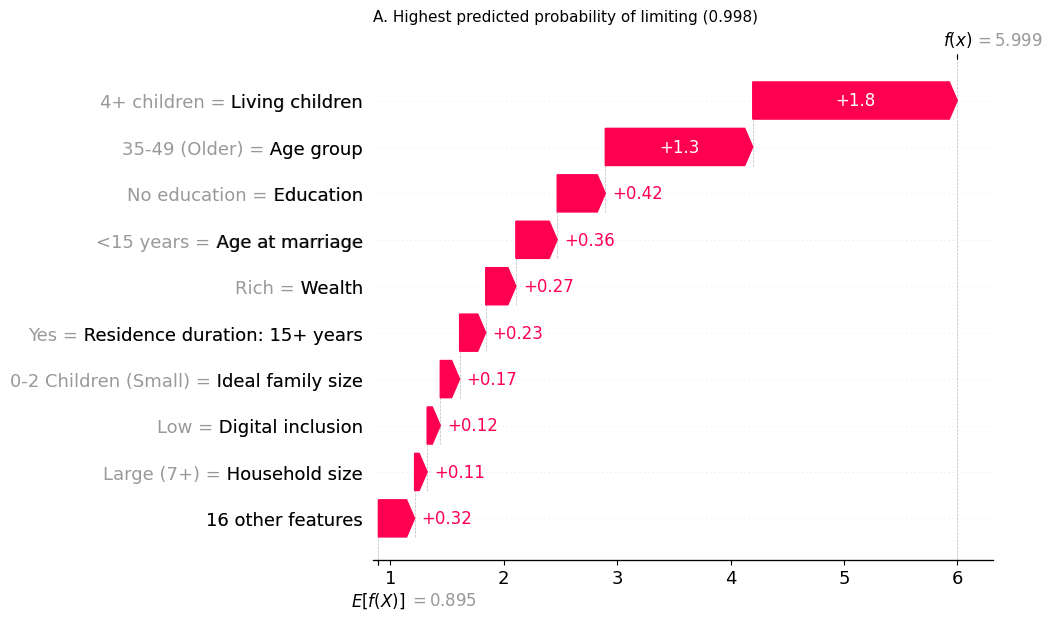

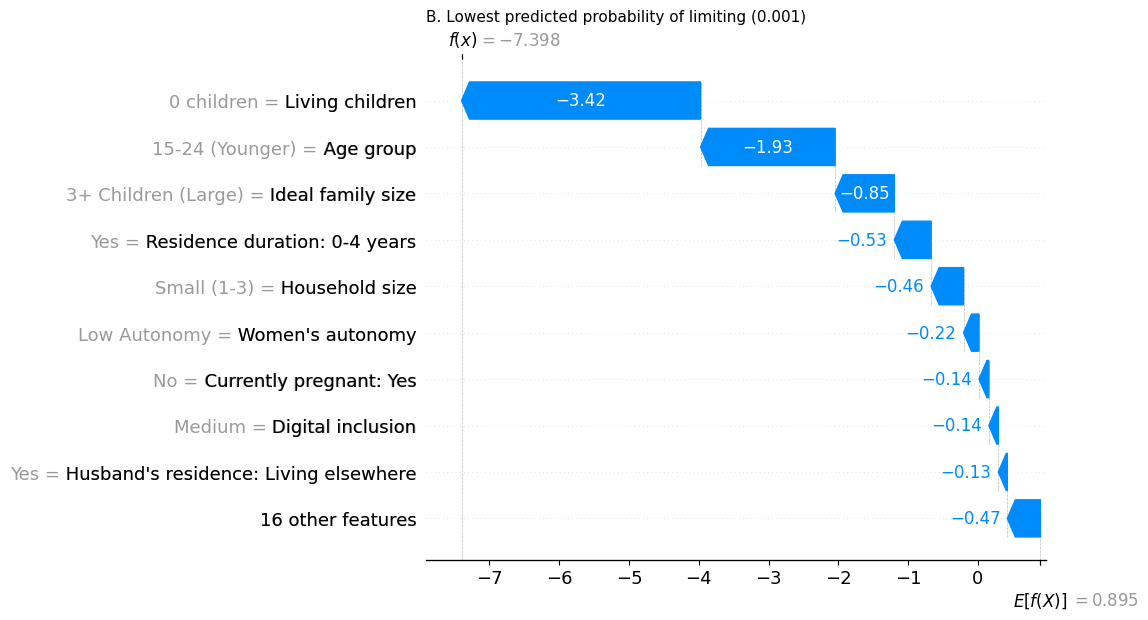

In [42]:
readable = pd.DataFrame({label: test_df[owner[f]].astype(str).to_numpy() if f == owner[f]
                         else np.where(X_test[f].to_numpy() == 1, "Yes", "No")
                         for f, label in zip(final_features, labels)})
sv_local = shap.Explanation(sv.values, base_values=sv.base_values, data=readable.to_numpy(), feature_names=labels)

for panel, label, i in [("A", "Highest", np.argmax(test_prob["XGBoost"])),
                        ("B", "Lowest", np.argmin(test_prob["XGBoost"]))]:
    shap.plots.waterfall(sv_local[i], max_display=10, show=False)
    plt.title(f"{panel}. {label} predicted probability of limiting ({test_prob['XGBoost'][i]:.3f})",
              loc="left", fontsize=11)
    plt.savefig(f"../output/fig_s3{panel.lower()}_local_{label.lower()}.png", dpi=300, bbox_inches="tight")
    plt.show()


## SHAP values of pregnancy and ideal family size

In [43]:
check = pd.DataFrame({"Living children": test_df["living_children_cat"].to_numpy(),
                      "Pregnant": test_df["is_pregnant"].to_numpy(),
                      "Ideal family size": test_df["ideal_family_size_cat"].to_numpy(),
                      "SHAP pregnancy": sv[:, "is_pregnant_Yes"].values,
                      "SHAP ideal family size": sv[:, "ideal_family_size_cat"].values})

display(check.groupby(["Living children", "Pregnant"], observed=True)["SHAP pregnancy"].agg(["mean", "size"]).round(3))
check.groupby(["Living children", "Ideal family size"], observed=True)["SHAP ideal family size"].agg(["mean", "size"]).round(3)


mean  size
Living children Pregnant             
0 children      No       -0.106   282
                Yes       0.932    75
1-3 children    No       -0.074  2589
                Yes       0.710   133
4+ children     No       -0.052   358
                Yes       0.415     6

mean  size
Living children Ideal family size                
0 children      0-2 Children (Small)  0.235   306
                3+ Children (Large)  -0.847    51
1-3 children    0-2 Children (Small)  0.209  2135
                3+ Children (Large)  -0.750   587
4+ children     0-2 Children (Small)  0.169   160
                3+ Children (Large)  -0.611   204

## XGBoost and CatBoost on the test set

In [44]:
d_catboost = boot_test["XGBoost"] - boot_test["CatBoost"]
pd.Series({"difference": auc["XGBoost"] - auc["CatBoost"],
           "2.5%": d_catboost.quantile(0.025), "97.5%": d_catboost.quantile(0.975)}).round(3)

difference    0.000
2.5%         -0.001
97.5%         0.002
dtype: float64

## Excluding undecided women: prevalence

In [45]:
limiting = df["target"] == "Limiting"
decided = df["undecided"] == 0
pd.Series({"all women": df.loc[limiting, "weight"].sum() / df["weight"].sum() * 100,
           "excluding undecided": df.loc[limiting & decided, "weight"].sum() / df.loc[decided, "weight"].sum() * 100}).round(1)

all women              60.9
excluding undecided    64.9
dtype: float64

## Skipped digital items

In [46]:
pd.DataFrame({"women": [(df["owns_mobile"] == 0).sum(), (df["dig_account"] == 0).sum()],
              "%": [(df["owns_mobile"] == 0).mean() * 100, (df["dig_account"] == 0).mean() * 100]},
             index=["No mobile phone (smartphone item skipped)", "No account (account use item skipped)"]).round(1)

,women,%
No mobile phone (smartphone item skipped),5297,30.7
No account (account use item skipped),13817,80.1


## Contraceptive method type

In [47]:
counts = pd.crosstab(df["contra_method_type"], df["target"])
counts["% limiting"] = (counts["Limiting"] / counts.sum(axis=1) * 100).round(1)
counts.to_csv("../output/contraceptive_method_type.csv")
counts

target,Limiting,Non-Limiting,% limiting
contra_method_type,,,
None,2487,3112,44.4
Permanent,998,0,100.0
Reversible,7081,3567,66.5


## Sensitivity analyses

In [48]:
def rerun(keep, predictors):
    data = df[predictors].copy()
    if "contra_behavior_intent" in predictors:
        data["contra_behavior_intent"] = pd.Categorical(data["contra_behavior_intent"],
                                                        categories=order["contra_behavior_intent"])
    for c in ORDINAL:
        if c in predictors:
            data[c] = data[c].cat.codes
    data = pd.get_dummies(data, columns=[c for c in predictors if c in NOMINAL or c == "contra_behavior_intent"],
                          drop_first=True, dtype=int)

    tr, te = train_idx[keep[train_idx]], test_idx[keep[test_idx]]
    X_tr, X_te, y_tr, y_te = data.iloc[tr], data.iloc[te], y[tr], y[te]
    psu = df["psu"].to_numpy()
    g_tr, g_te = psu[tr], psu[te]

    # Nested cross-validation with Boruta and tuning inside each training fold
    fold_aucs = {name: [] for name in models}
    for a, b in StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED).split(X_tr, y_tr, groups=g_tr):
        rf = RandomForestClassifier(n_jobs=-1, max_depth=5, random_state=SEED)
        boruta = BorutaPy(rf, n_estimators="auto", max_iter=100, random_state=SEED)
        boruta.fit(X_tr.iloc[a].to_numpy(float), y_tr[a])
        cols = X_tr.columns[boruta.support_].tolist()
        for name, (model, grid, n_iter) in models.items():
            search = RandomizedSearchCV(model, grid, n_iter=n_iter, cv=inner_cv,
                                        scoring="roc_auc", random_state=SEED, n_jobs=-1)
            search.fit(X_tr.iloc[a][cols], y_tr[a], groups=g_tr[a])
            fold_aucs[name].append(roc_auc_score(y_tr[b], search.predict_proba(X_tr.iloc[b][cols])[:, 1]))
    cv_auc = pd.DataFrame(fold_aucs).agg(["mean", "std"]).T

    # Final Boruta and tuning on the whole training set
    rf = RandomForestClassifier(n_jobs=-1, max_depth=5, random_state=SEED)
    boruta = BorutaPy(rf, n_estimators="auto", max_iter=100, random_state=SEED)
    boruta.fit(X_tr.to_numpy(float), y_tr)
    cols = X_tr.columns[boruta.support_].tolist()

    # Cluster bootstrap of the test set
    boot_rng = np.random.default_rng(SEED)
    clusters = np.unique(g_te)
    rows_in = {g: np.where(g_te == g)[0] for g in clusters}
    resamples = [np.concatenate([rows_in[g] for g in boot_rng.choice(clusters, size=len(clusters), replace=True)])
                 for _ in range(1000)]

    rows = []
    for name in cv_auc["mean"].sort_values(ascending=False).index:
        model, grid, n_iter = models[name]
        search = RandomizedSearchCV(model, grid, n_iter=n_iter, cv=inner_cv, scoring="roc_auc",
                                    random_state=SEED, n_jobs=-1)
        search.fit(X_tr[cols], y_tr, groups=g_tr)
        p = np.clip(search.predict_proba(X_te[cols])[:, 1], 1e-6, 1 - 1e-6)
        tn, fp, fn, tp = confusion_matrix(y_te, p >= 0.5).ravel()
        cal = calibration(y_te, p)
        cal_boot = pd.DataFrame([calibration(y_te[i], p[i]) for i in resamples])
        auc_boot = [roc_auc_score(y_te[i], p[i]) for i in resamples]
        rows.append({
            "Model": name, "Women (train)": len(tr), "Women (test)": len(te), "Final features": len(cols),
            "CV AUC (mean ± SD)": f"{cv_auc.loc[name, 'mean']:.3f} ± {cv_auc.loc[name, 'std']:.3f}",
            "Test AUC (95% CI)": f"{roc_auc_score(y_te, p):.3f} ({np.quantile(auc_boot, 0.025):.3f}–{np.quantile(auc_boot, 0.975):.3f})",
            "PR-AUC": f"{average_precision_score(y_te, p):.3f}",
            "Accuracy": f"{(tp + tn) / len(y_te) * 100:.1f}",
            "Precision": f"{tp / (tp + fp) * 100:.1f}",
            "Sensitivity": f"{tp / (tp + fn) * 100:.1f}",
            "Specificity": f"{tn / (tn + fp) * 100:.1f}",
            "F1-score": f"{2 * tp / (2 * tp + fp + fn):.3f}"} | {
            label: f"{cal[k]:.3f} ({cal_boot[k].quantile(0.025):.3f}–{cal_boot[k].quantile(0.975):.3f})"
            for label, k in [("Brier score (95% CI)", "Brier"), ("Calibration intercept (95% CI)", "intercept"),
                             ("Calibration slope (95% CI)", "slope")]})
    return pd.DataFrame(rows)

sensitivity = {}

In [49]:
sensitivity["Excluding sterilized women"] = rerun((df["sterilized"] == 0).to_numpy(), PREDICTORS)
sensitivity["Excluding sterilized women"]

,Model,Women (train),Women (test),Final features,CV AUC (mean ± SD),Test AUC (95% CI),PR-AUC,Accuracy,Precision,Sensitivity,Specificity,F1-score,Brier score (95% CI),Calibration intercept (95% CI),Calibration slope (95% CI)
0,XGBoost,13005,3242,25,0.901 ± 0.010,0.901 (0.888–0.911),0.923,82.2,82.8,87.8,74.2,0.852,0.124 (0.117–0.132),0.038 (-0.065–0.135),1.040 (0.963–1.125)
1,CatBoost,13005,3242,25,0.900 ± 0.009,0.902 (0.889–0.913),0.925,82.0,82.4,88.1,73.4,0.851,0.123 (0.117–0.131),0.031 (-0.068–0.128),1.098 (1.020–1.183)
2,Random Forest,13005,3242,25,0.894 ± 0.010,0.892 (0.879–0.904),0.913,81.8,82.4,87.7,73.4,0.850,0.129 (0.122–0.136),0.040 (-0.058–0.137),1.099 (1.017–1.188)
3,Logistic Regression,13005,3242,25,0.893 ± 0.010,0.896 (0.883–0.908),0.921,81.1,82.3,86.3,73.8,0.843,0.127 (0.120–0.135),0.038 (-0.067–0.137),1.041 (0.961–1.128)
4,SVM,13005,3242,25,0.892 ± 0.010,0.894 (0.881–0.906),0.916,81.9,82.5,87.7,73.6,0.850,0.128 (0.121–0.137),0.017 (-0.090–0.118),1.000 (0.940–1.067)


In [50]:
sensitivity["Excluding undecided women"] = rerun((df["undecided"] == 0).to_numpy(), PREDICTORS)
sensitivity["Excluding undecided women"]

,Model,Women (train),Women (test),Final features,CV AUC (mean ± SD),Test AUC (95% CI),PR-AUC,Accuracy,Precision,Sensitivity,Specificity,F1-score,Brier score (95% CI),Calibration intercept (95% CI),Calibration slope (95% CI)
0,XGBoost,12935,3241,26,0.921 ± 0.009,0.919 (0.908–0.928),0.951,84.6,85.7,91.6,71.8,0.885,0.106 (0.099–0.113),-0.017 (-0.123–0.083),1.028 (0.960–1.112)
1,CatBoost,12935,3241,26,0.921 ± 0.010,0.919 (0.909–0.929),0.951,84.7,85.6,91.9,71.5,0.886,0.106 (0.099–0.112),-0.026 (-0.128–0.072),1.039 (0.971–1.120)
2,Logistic Regression,12935,3241,26,0.914 ± 0.011,0.914 (0.903–0.924),0.949,84.0,85.4,90.9,71.4,0.881,0.110 (0.103–0.118),-0.029 (-0.143–0.078),1.011 (0.940–1.089)
3,Random Forest,12935,3241,26,0.913 ± 0.009,0.908 (0.897–0.919),0.943,84.3,84.8,92.3,69.4,0.884,0.111 (0.105–0.118),0.011 (-0.084–0.107),1.110 (1.037–1.196)
4,SVM,12935,3241,26,0.912 ± 0.011,0.910 (0.898–0.921),0.944,84.5,85.3,91.9,70.8,0.885,0.112 (0.105–0.120),-0.036 (-0.145–0.069),0.970 (0.908–1.041)


In [51]:
everyone = np.ones(len(df), dtype=bool)
sensitivity["Adding contraceptive use and intention"] = rerun(everyone, PREDICTORS + ["contra_behavior_intent"])
sensitivity["Adding contraceptive use and intention"]

,Model,Women (train),Women (test),Final features,CV AUC (mean ± SD),Test AUC (95% CI),PR-AUC,Accuracy,Precision,Sensitivity,Specificity,F1-score,Brier score (95% CI),Calibration intercept (95% CI),Calibration slope (95% CI)
0,CatBoost,13802,3443,27,0.915 ± 0.007,0.919 (0.908–0.929),0.945,83.8,84.9,89.3,75.2,0.871,0.111 (0.104–0.118),0.035 (-0.072–0.141),1.100 (1.023–1.189)
1,XGBoost,13802,3443,27,0.915 ± 0.007,0.918 (0.907–0.928),0.944,83.5,84.7,89.1,74.9,0.868,0.111 (0.104–0.119),0.038 (-0.069–0.142),1.092 (1.012–1.181)
2,Random Forest,13802,3443,27,0.908 ± 0.006,0.910 (0.898–0.920),0.936,83.5,84.7,89.0,74.9,0.868,0.117 (0.110–0.124),0.034 (-0.063–0.130),1.162 (1.077–1.263)
3,Logistic Regression,13802,3443,27,0.908 ± 0.007,0.914 (0.903–0.925),0.942,83.8,85.4,88.6,76.2,0.870,0.114 (0.107–0.122),0.047 (-0.070–0.155),1.044 (0.970–1.132)
4,SVM,13802,3443,27,0.907 ± 0.006,0.911 (0.900–0.921),0.939,83.3,84.7,88.6,74.9,0.866,0.117 (0.109–0.125),0.025 (-0.094–0.136),0.997 (0.939–1.068)


In [52]:
digital_items = ["dig_internet", "dig_smartphone", "dig_account", "dig_account_use"]
sensitivity["Digital items instead of index"] = rerun(
    everyone, [c for c in PREDICTORS if c != "digital_inclusion_cat"] + digital_items)
sensitivity["Digital items instead of index"]

,Model,Women (train),Women (test),Final features,CV AUC (mean ± SD),Test AUC (95% CI),PR-AUC,Accuracy,Precision,Sensitivity,Specificity,F1-score,Brier score (95% CI),Calibration intercept (95% CI),Calibration slope (95% CI)
0,XGBoost,13802,3443,28,0.905 ± 0.007,0.908 (0.896–0.918),0.936,83.2,84.1,89.3,73.5,0.866,0.118 (0.111–0.126),0.025 (-0.077–0.123),1.054 (0.979–1.138)
1,CatBoost,13802,3443,28,0.905 ± 0.007,0.908 (0.897–0.919),0.937,82.9,83.6,89.5,72.5,0.864,0.117 (0.110–0.125),0.018 (-0.083–0.116),1.061 (0.987–1.143)
2,Random Forest,13802,3443,28,0.899 ± 0.008,0.898 (0.885–0.909),0.925,82.5,83.4,89.1,72.3,0.861,0.123 (0.117–0.131),0.042 (-0.053–0.139),1.131 (1.052–1.227)
3,Logistic Regression,13802,3443,28,0.898 ± 0.007,0.903 (0.891–0.914),0.934,81.8,83.4,87.6,72.6,0.855,0.122 (0.114–0.129),0.022 (-0.085–0.124),1.045 (0.967–1.130)
4,SVM,13802,3443,28,0.896 ± 0.007,0.900 (0.888–0.911),0.929,82.4,83.3,89.0,72.0,0.860,0.123 (0.116–0.132),0.017 (-0.093–0.121),1.002 (0.940–1.069)


In [53]:
sensitivity_table = pd.concat(sensitivity, names=["Analysis"]).reset_index(level=0).reset_index(drop=True)
sensitivity_table.to_csv("../output/sensitivity_analyses.csv", index=False)
sensitivity_table

,Analysis,Model,Women (train),Women (test),Final features,CV AUC (mean ± SD),Test AUC (95% CI),PR-AUC,Accuracy,Precision,Sensitivity,Specificity,F1-score,Brier score (95% CI),Calibration intercept (95% CI),Calibration slope (95% CI)
0,Excluding sterilized women,XGBoost,13005,3242,25,0.901 ± 0.010,0.901 (0.888–0.911),0.923,82.2,82.8,87.8,74.2,0.852,0.124 (0.117–0.132),0.038 (-0.065–0.135),1.040 (0.963–1.125)
1,Excluding sterilized women,CatBoost,13005,3242,25,0.900 ± 0.009,0.902 (0.889–0.913),0.925,82.0,82.4,88.1,73.4,0.851,0.123 (0.117–0.131),0.031 (-0.068–0.128),1.098 (1.020–1.183)
2,Excluding sterilized women,Random Forest,13005,3242,25,0.894 ± 0.010,0.892 (0.879–0.904),0.913,81.8,82.4,87.7,73.4,0.850,0.129 (0.122–0.136),0.040 (-0.058–0.137),1.099 (1.017–1.188)
3,Excluding sterilized women,Logistic Regression,13005,3242,25,0.893 ± 0.010,0.896 (0.883–0.908),0.921,81.1,82.3,86.3,73.8,0.843,0.127 (0.120–0.135),0.038 (-0.067–0.137),1.041 (0.961–1.128)
4,Excluding sterilized women,SVM,13005,3242,25,0.892 ± 0.010,0.894 (0.881–0.906),0.916,81.9,82.5,87.7,73.6,0.850,0.128 (0.121–0.137),0.017 (-0.090–0.118),1.000 (0.940–1.067)
5,Excluding undecided women,XGBoost,12935,3241,26,0.921 ± 0.009,0.919 (0.908–0.928),0.951,84.6,85.7,91.6,71.8,0.885,0.106 (0.099–0.113),-0.017 (-0.123–0.083),1.028 (0.960–1.112)
6,Excluding undecided women,CatBoost,12935,3241,26,0.921 ± 0.010,0.919 (0.909–0.929),0.951,84.7,85.6,91.9,71.5,0.886,0.106 (0.099–0.112),-0.026 (-0.128–0.072),1.039 (0.971–1.120)
7,Excluding undecided women,Logistic Regression,12935,3241,26,0.914 ± 0.011,0.914 (0.903–0.924),0.949,84.0,85.4,90.9,71.4,0.881,0.110 (0.103–0.118),-0.029 (-0.143–0.078),1.011 (0.940–1.089)
8,Excluding undecided women,Random Forest,12935,3241,26,0.913 ± 0.009,0.908 (0.897–0.919),0.943,84.3,84.8,92.3,69.4,0.884,0.111 (0.105–0.118),0.011 (-0.084–0.107),1.110 (1.037–1.196)
9,Excluding undecided women,SVM,12935,3241,26,0.912 ± 0.011,0.910 (0.898–0.921),0.944,84.5,85.3,91.9,70.8,0.885,0.112 (0.105–0.120),-0.036 (-0.145–0.069),0.970 (0.908–1.041)


## Software versions

In [54]:
import sys
from importlib.metadata import version

pd.Series({"Python": sys.version.split()[0]} |
          {pkg: version(pkg) for pkg in ["numpy", "pandas", "scikit-learn", "scipy", "statsmodels",
                                         "xgboost", "catboost", "Boruta", "shap", "matplotlib"]})

Python          3.13.6
numpy            2.3.3
pandas           2.3.2
scikit-learn     1.7.2
scipy           1.17.1
statsmodels     0.15.0
xgboost          3.2.0
catboost        1.2.10
Boruta           0.4.3
shap            0.52.0
matplotlib      3.10.8
dtype: object